# SPARQL Pattern Matching For Analysis

This notebook demonstrates the first analytical pipeline. The goal is to leverage the rich, interconnected structure of our Knowledge Graph to answer complex questions and uncover interesting patterns. This allows us to perform some data analysis on our graph.

We will connect to our running GraphDB SPARQL endpoint and execute a series of queries that would be difficult or inefficient to perform using traditional SQL on the original relational data.

First of all, we can observe our graph using GraphDB. We see how we have the different movies, properties (relationships to literals, like name)... We can observe how different movies can be related, for example, using genre or collection. We also see how we have been able to successfully integrate the soundtracks and ratings into our original movies database.

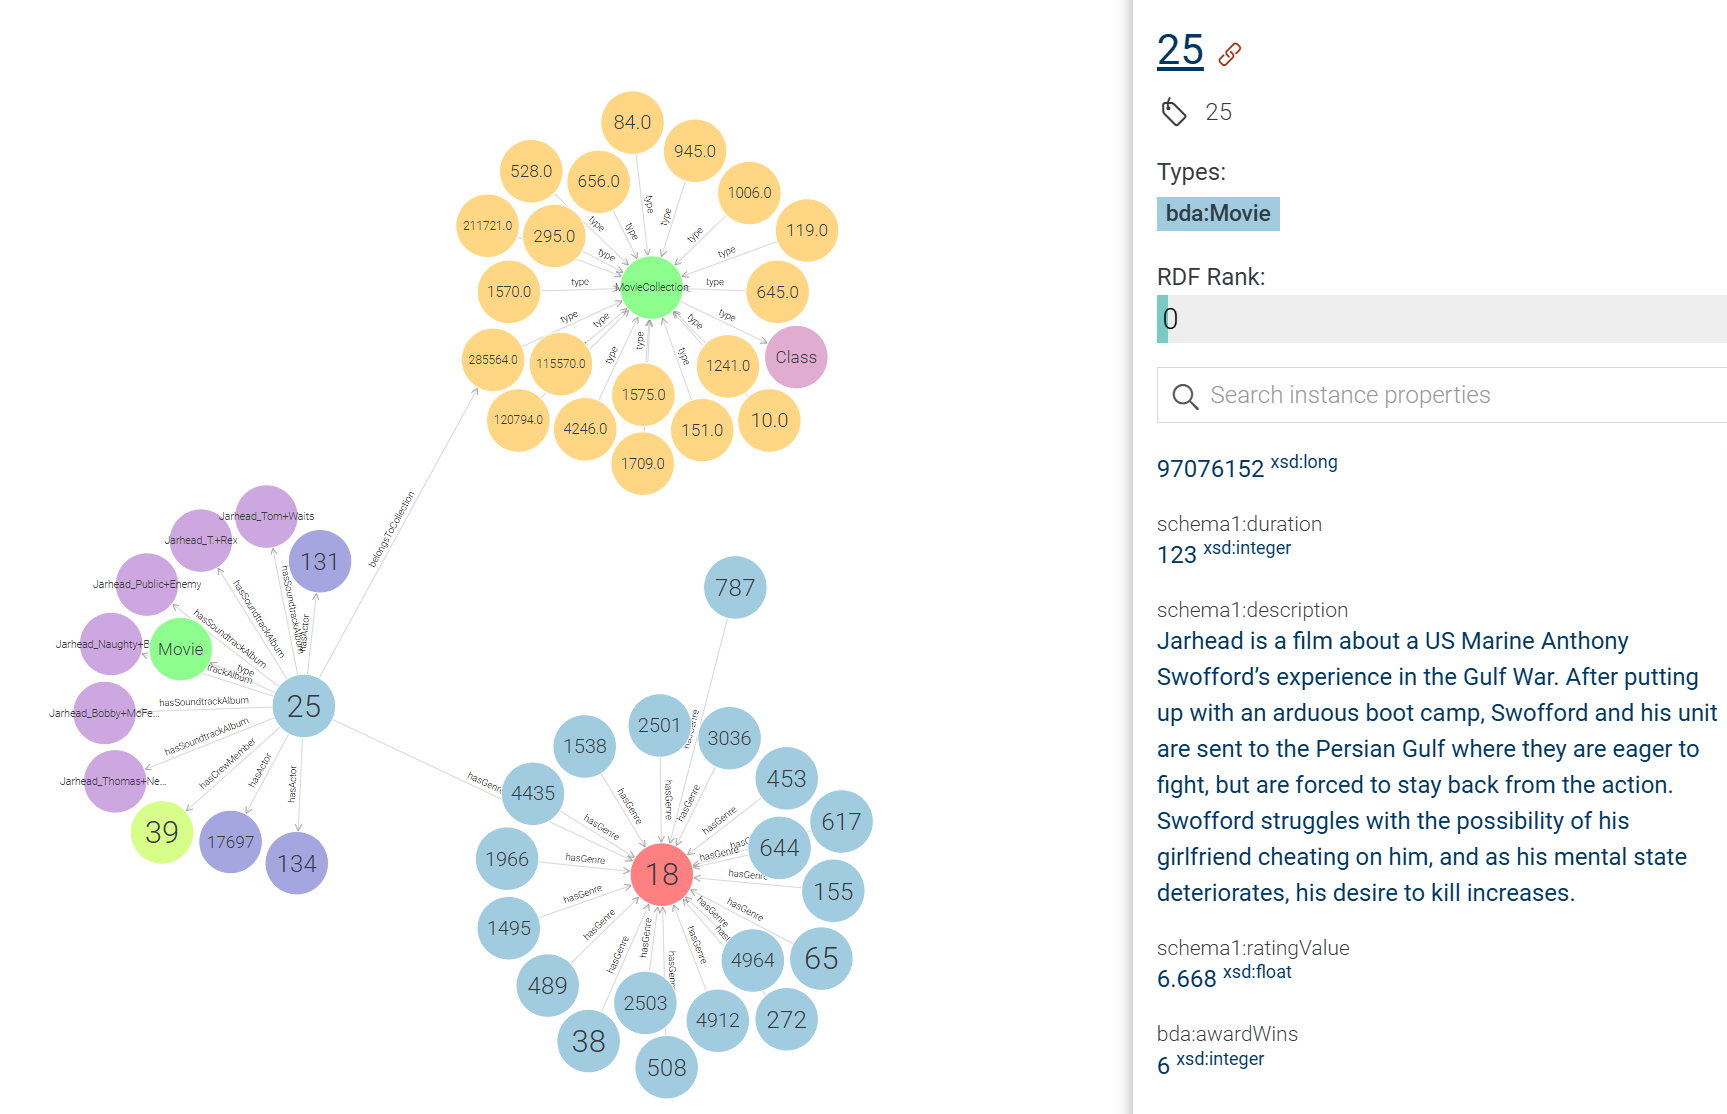

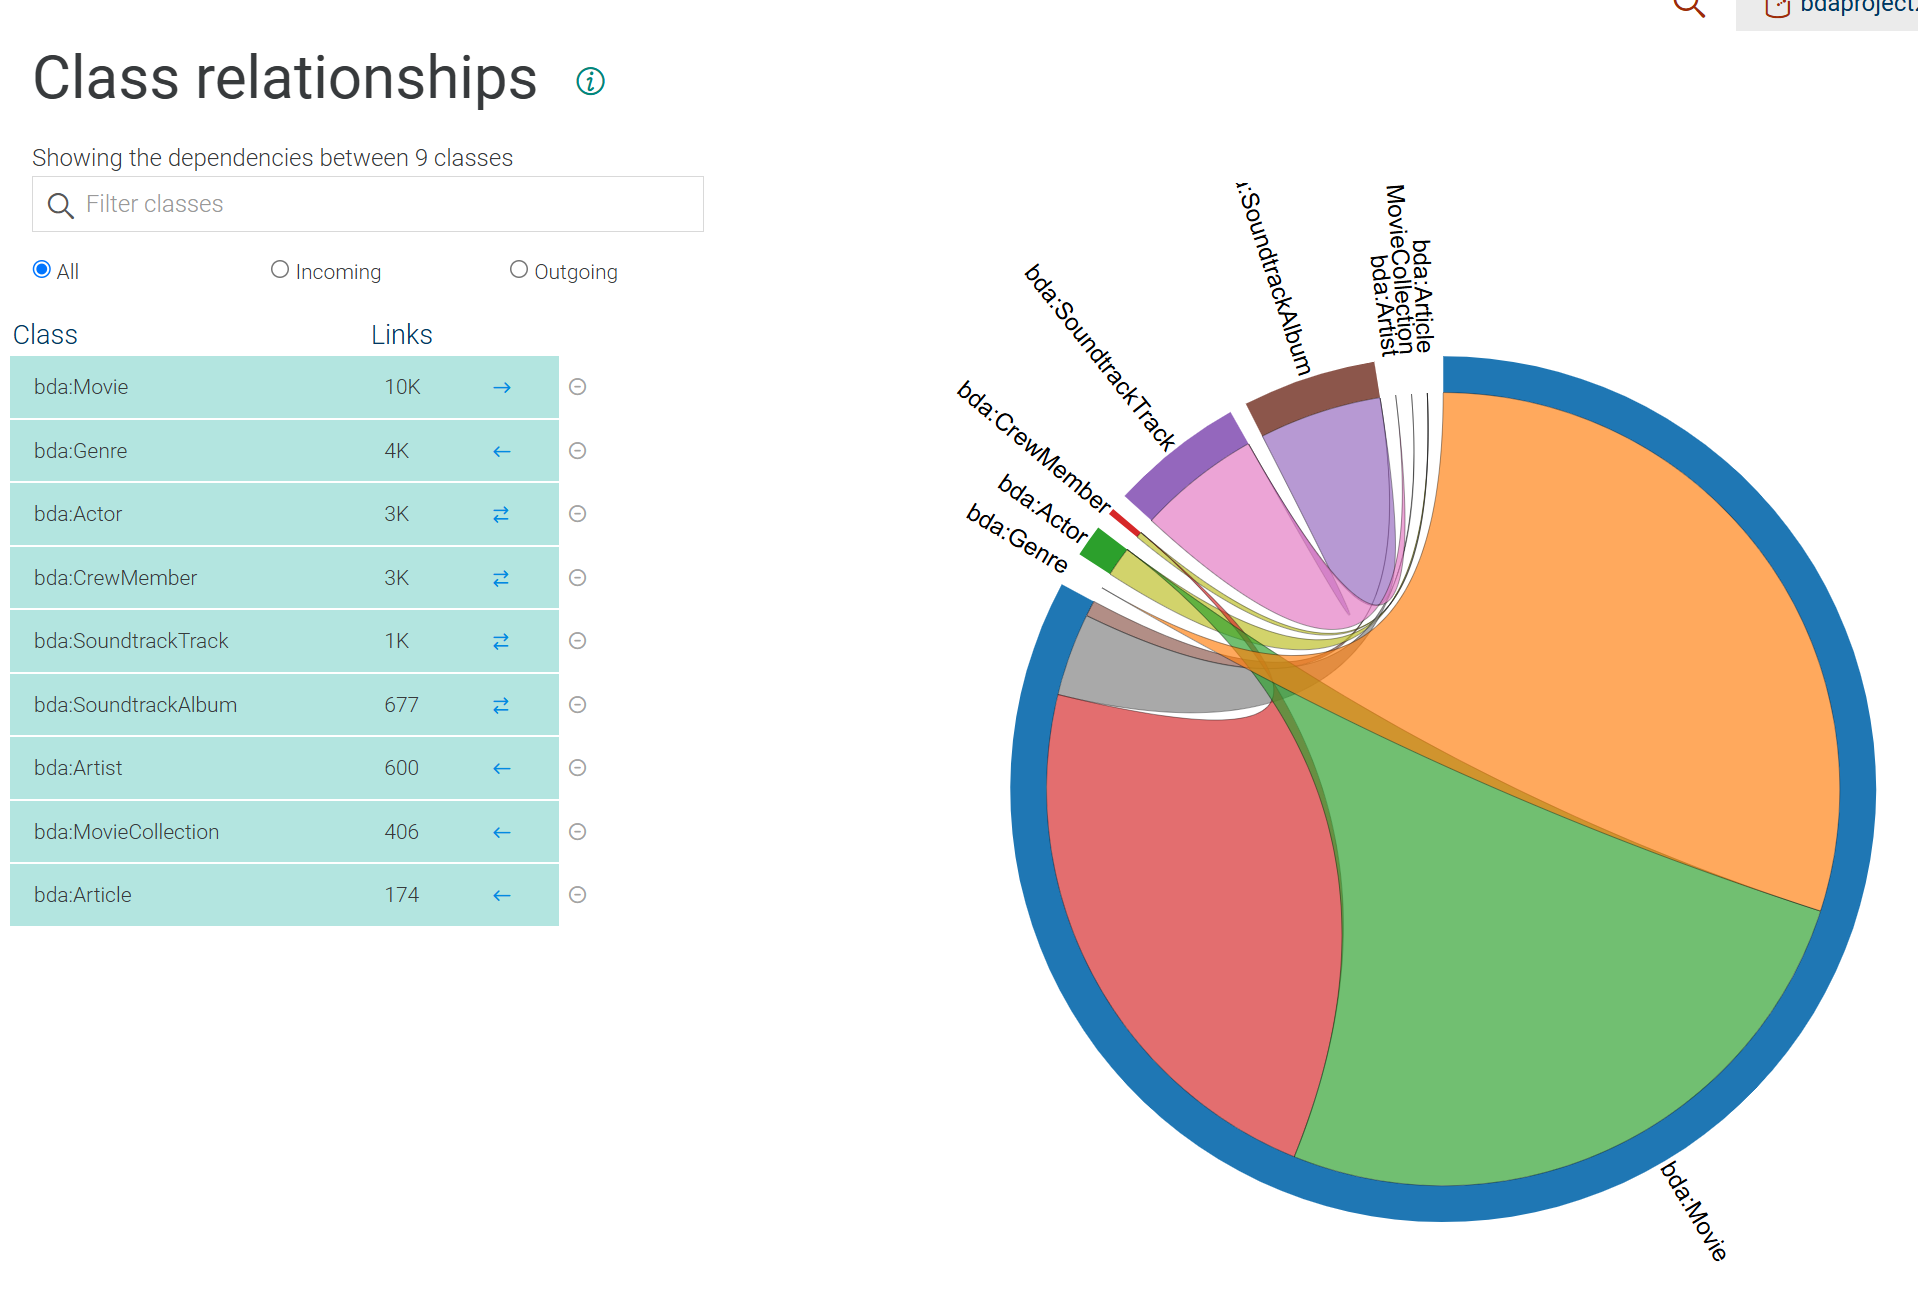

As expected, our main class is bda:Movie, which is basically the "center" of our relationships.

## 1. Setup and Configuration

First, we install and import the necessary libraries. `SPARQLWrapper` is the key library for connecting to the endpoint, and `pandas` will be used to display the query results in a clean, tabular format.

In [ ]:
!pip install SPARQLWrapper pandas

In [7]:
import pandas as pd
from SPARQLWrapper import SPARQLWrapper, JSON

GRAPHDB_REPOSITORY_NAME = "bdaproject2"
SPARQL_ENDPOINT = f"http://localhost:7200/repositories/{GRAPHDB_REPOSITORY_NAME}"

print(f"SPARQL endpoint set to: {SPARQL_ENDPOINT}")

SPARQL endpoint set to: http://localhost:7200/repositories/bdaproject2


## 2. Helper Function for Querying
Takes a SPARQL query string, executes it against our endpoint, and returns the results as a pandas DataFrame.

In [8]:
def execute_sparql_query(endpoint, query):
    sparql = SPARQLWrapper(endpoint)
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    
    try:
        response = sparql.query().convert()
        results = response["results"]["bindings"]
        
        processed_results = []
        for r in results:
            row = {key: value['value'] for key, value in r.items()}
            processed_results.append(row)
            
        return pd.DataFrame(processed_results)
        
    except Exception as e:
        print(f"An error occurred: {e}")
        return None

## 3. Analytical Queries

Now we will run our insightful queries.

### Query 1: Identifying Top Actor-Director Collaborations

**Goal:** Identify the most prolific actor-director partnerships. This helps us understand successful collaborations in the film industry. We will look for pairs who have worked on 3 or more films together and calculate the average box office revenue.

In [19]:
query_a = """
    PREFIX bda: <http://www.bdaproject.org/schema#>
    PREFIX foaf: <http://xmlns.com/foaf/0.1/>
    PREFIX dbo: <http://dbpedia.org/ontology/>

    SELECT ?actorName ?directorName (COUNT(?movie) as ?collaborationCount) (AVG(xsd:long(?revenue)) as ?averageRevenue)
    WHERE {
        ?movie a bda:Movie ;
               bda:hasActor ?actor ;
               bda:hasCrewMember ?director ;
               dbo:revenue ?revenue .
        
        ?actor foaf:name ?actorName .
        ?director foaf:name ?directorName ;
                  bda:job "Director" .

    }
    GROUP BY ?actorName ?directorName
    HAVING (COUNT(?movie) > 2)
    ORDER BY DESC(?collaborationCount) DESC(?averageRevenue)
    LIMIT 10
"""

print("--- Executing Query 1: Top Actor-Director Collaborations ---")
creative_core_df = execute_sparql_query(SPARQL_ENDPOINT, query_a)
display(creative_core_df)

--- Executing Query 1: Top Actor-Director Collaborations ---


,actorName,directorName,collaborationCount,averageRevenue
0,Sylvester Stallone,Sylvester Stallone,10,178742955.8
1,George Clooney,Steven Soderbergh,10,151301794.6
2,Harrison Ford,George Lucas,8,501278977.125
3,Robert De Niro,Martin Scorsese,7,57529744.857142857142857142857143
4,Quentin Tarantino,Quentin Tarantino,7,52020850.142857142857142857142857
5,Matt Damon,Steven Soderbergh,6,226177079.833333333333333333333333
6,Sylvester Stallone,Irwin Winkler,6,192790505.166666666666666666666667
7,Robert De Niro,Robert De Niro,6,190149710
8,Sofia Coppola,Francis Ford Coppola,6,91092220.166666666666666666666667
9,Ben Affleck,Kevin Smith,6,55358283.333333333333333333333333


As expected, we have names of big actors and directors, which usually generate a lot of revenue. It is interesting to see how, for example, Sylvester Stallone has directed himself a lot of times and with high revenue (also Quentin Tarantino).

### Query 2: Finding the Most Versatile Actors

**Analytical Goal:** Since we have actors that have starred in a lot of different movies, we can try to dentify those who have demonstrated versatility by starring across a wide range of genres. 

This query could help talent scouts or casting directors find flexible actors. We'll look for actors who have appeared in at least 4 distinct genres.

In [18]:
query_b = """
    PREFIX bda: <http://www.bdaproject.org/schema#>
    PREFIX foaf: <http://xmlns.com/foaf/0.1/>
    PREFIX schema: <http://schema.org/>

    SELECT ?actorName (COUNT(DISTINCT ?genreName) as ?genreCount)
    WHERE {
      ?movie bda:hasActor ?actor .
      ?movie bda:hasGenre ?genre .
      ?actor foaf:name ?actorName .
      ?genre schema:name ?genreName .
    }
    GROUP BY ?actorName
    HAVING (COUNT(DISTINCT ?genreName) >= 4)
    ORDER BY DESC(?genreCount)
    LIMIT 15
"""

print("--- Executing Query 2: Most Versatile Actors ---")
versatile_actors_df = execute_sparql_query(SPARQL_ENDPOINT, query_b)
display(versatile_actors_df)

--- Executing Query 2: Most Versatile Actors ---


,actorName,genreCount
0,Johnny Depp,16
1,Brad Pitt,15
2,Keanu Reeves,15
3,John Hurt,15
4,Jack Black,14
5,Robert De Niro,14
6,Ewan McGregor,14
7,Laurence Fishburne,14
8,Antonio Banderas,14
9,Nicole Kidman,14


The list highlights actors who are not typecast and have a broad portfolio. Johnny Depp, in our database, is the most versatile one.

<img src="https://pbs.twimg.com/media/GkYhw8LWwAA0q3j.jpg:large" alt="Johnny Depp versatility chart" width="300"/>

An actor with a high `genreCount` is a valuable asset, capable of fitting into many different types of productions.

We can also find which genres are those where Johnny Depp has acted:

In [ ]:
query_b2 = """
    PREFIX bda: <http://www.bdaproject.org/schema#>
    PREFIX foaf: <http://xmlns.com/foaf/0.1/>
    PREFIX schema: <http://schema.org/>

    SELECT DISTINCT ?genreName
    WHERE {
      ?movie bda:hasActor ?actor .
      ?movie bda:hasGenre ?genre .
      ?actor foaf:name ?actorName .
      ?genre schema:name ?genreName .
      FILTER regex(?actorName, "Johnny Depp")
    }
    
"""

print("--- Executing Query 2-2: Johnny Depp ---")
versatile_actors_df = execute_sparql_query(SPARQL_ENDPOINT, query_b2)
display(versatile_actors_df)

--- Executing Query B2: Johnny Depp ---


,genreName
0,Drama
1,Romance
2,Fantasy
3,Action
4,Adventure
5,War
6,Comedy
7,History
8,Horror
9,Crime


### Query 3: Artists on Award-Winning Films

**Goal:** Discover which music artists or composers are most frequently featured on the soundtracks of critically acclaimed (award-winning) films. This could suggest a correlation between certain musical styles and cinematic success.

This allows us to connect the Omdb database, which had information about award-winning films with the spotify one, through the movies database (showcasing the data integration capabilities of KGs)

In [17]:
query_c = """
    PREFIX bda: <http://www.bdaproject.org/schema#>
    PREFIX foaf: <http://xmlns.com/foaf/0.1/>

    SELECT ?artistName (COUNT(?movie) as ?awardWinningMovieCount)
    WHERE {
      ?movie a bda:Movie ;
             bda:awardWins ?wins .
      
      # Use property paths for a concise traversal!
      ?movie bda:hasSoundtrackAlbum/bda:hasTrack/bda:performedBy ?artist .
      
      ?artist foaf:name ?artistName .
      FILTER(?wins > 0)
    }
    GROUP BY ?artistName
    ORDER BY DESC(?awardWinningMovieCount)
    LIMIT 10
"""

print("--- Executing Query 3: Artists on Award-Winning Film Soundtracks ---")
soundtrack_success_df = execute_sparql_query(SPARQL_ENDPOINT, query_c)
display(soundtrack_success_df)

--- Executing Query 3: Artists on Award-Winning Film Soundtracks ---


,artistName,awardWinningMovieCount
0,Thomas Newman,59
1,The Simpsons,49
2,The Monkees,30
3,Éric Serra,27
4,Tony Bremner,21
5,Alan Silvestri,21
6,Jon Brion,17
7,Corona,16
8,Klaus Badelt,15
9,SFDK,15


Interestingly, some of famous songwritters do not appear. This is due to the fact that our original soundtrack dataset was limited by how well the spotify API worked, and that's why composers like John Williams do not appear.

### Query 4: Six Degrees of Separation - Finding a Path Between Two Actors

**Goal:** Six degrees of separation is the idea that all people are six or fewer social connections away from each other. With this query, we aim to demonstrate the core power of graph traversal by finding a collaborative path between two actors who have not worked together directly.

For example, we can find a path of length 2 (i.e., through one intermediary actor) between 'Tom Hanks' and 'Cillian Murphy'.

In [20]:
query_d = """
    PREFIX bda: <http://www.bdaproject.org/schema#>
    PREFIX foaf: <http://xmlns.com/foaf/0.1/>
    PREFIX schema: <http://schema.org/>

    SELECT DISTINCT ?startActorName ?movie1Name ?connectingActorName ?movie2Name ?endActorName
    WHERE {
      ?startActor foaf:name ?startActorName .
      ?endActor foaf:name ?endActorName .
      
      # Find the path
      ?movie1 bda:hasActor ?startActor, ?connectingActor .
      ?movie2 bda:hasActor ?connectingActor, ?endActor .
      
      ?connectingActor foaf:name ?connectingActorName .
      ?movie1 schema:name ?movie1Name .
      ?movie2 schema:name ?movie2Name .

      FILTER(?startActor != ?connectingActor && ?connectingActor != ?endActor)
      FILTER(?movie1 != ?movie2)
      FILTER regex(?startActorName, "Tom Hanks")
      FILTER regex(?endActorName, "Cillian Murphy")
    }
    LIMIT 1
"""

print("--- Executing Query 4: Finding a Path between Tom Hanks and Cillian Murphy ---")
path_df = execute_sparql_query(SPARQL_ENDPOINT, query_d)

if path_df is not None and not path_df.empty:
    path = path_df.iloc[0]
    print("Path found!")
    print(f"{path['startActorName']} was in '{path['movie1Name']}' with {path['connectingActorName']}.")
    print(f"{path['connectingActorName']} was in '{path['movie2Name']}' with {path['endActorName']}.")
else:
    print("No direct path of length 2 found in the dataset.")

--- Executing Query 4: Finding a Path between Tom Hanks and Cillian Murphy ---
Path found!
Tom Hanks was in 'Road to Perdition' with Jude Law.
Jude Law was in 'Cold Mountain' with Cillian Murphy.


We can also create a code that traverses the graph to find deeper connections, up to 6 degrees of separation:

In [30]:
from collections import deque
import requests

In [31]:
def execute_sparql_query_list(endpoint, query):
    try:
        response = requests.get(
            endpoint,
            params={'query': query, 'format': 'json'},
            headers={'Accept': 'application/sparql-results+json'}
        )
        response.raise_for_status()
        results = response.json()
        return [
            {key: value['value'] for key, value in result.items()}
            for result in results['results']['bindings']
        ]
    except requests.exceptions.RequestException as e:
        print(f"Error executing SPARQL query: {e}")
        return None
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return None

In [ ]:
def get_actor_uri(actor_name, endpoint):
    """Finds the URI for an actor given their name."""
    print(f"Finding URI for '{actor_name}'...")
    query = f"""
        PREFIX foaf: <http://xmlns.com/foaf/0.1/>
        SELECT ?actor
        WHERE {{
          ?actor foaf:name ?actorName .
          FILTER regex(?actorName, "^{actor_name}$", "i")
        }}
        LIMIT 1
    """
    results = execute_sparql_query_list(endpoint, query)
    if results:
        uri = results[0]['actor']
        print(f" -> Found URI: {uri}")
        return uri
    else:
        print(f" -> Actor '{actor_name}' not found in the database.")
        return None

def hydrate_path(path_uris, endpoint):
    # Fetches the names of movies and actors from URIS
    uri_list_str = " ".join([f"<{uri}>" for uri in path_uris])
    
    query = f"""
        PREFIX foaf: <http://xmlns.com/foaf/0.1/>
        PREFIX schema: <http://schema.org/>

        SELECT ?uri ?name ?type
        WHERE {{
          VALUES ?uri {{ {uri_list_str} }}
          {{ 
            ?uri foaf:name ?name .
            BIND("actor" AS ?type)
          }}
          UNION
          {{
            ?uri schema:name ?name .
            BIND("movie" AS ?type)
          }}
        }}
    """
    # Bind allows us to distinguish if the relationship for the name is the
    # foaf one (the one used by actors) or the schema:name one,
    # which is used by movies
    results = execute_sparql_query_list(endpoint, query)
    if not results:
        return []
        
    uri_to_info = {item['uri']: {'name': item['name'], 'type': item['type']} for item in results}
    
    hydrated = []
    for uri in path_uris:
        info = uri_to_info.get(uri)
        if info:
            hydrated.append({'uri': uri, 'name': info['name'], 'type': info['type']})
        else:
            hydrated.append({'uri': uri, 'name': 'Unknown', 'type': 'unknown'})
            
    return hydrated

def print_path_nicely(hydrated_path):
    if not hydrated_path:
        return
        
    print("\n--- Path Found! ---")
    for i in range(0, len(hydrated_path) - 2, 2):
        actor1 = hydrated_path[i]['name']
        movie = hydrated_path[i+1]['name']
        actor2 = hydrated_path[i+2]['name']
        print(f"-> {actor1} was in '{movie}' with {actor2}.")
    print("-------------------\n")


def find_connection_bfs(start_actor_name, end_actor_name, endpoint, max_degrees=6):
    # This is a BFS :)
    print("--- Starting Actor Connection Search ---")
    start_uri = get_actor_uri(start_actor_name, endpoint)
    end_uri = get_actor_uri(end_actor_name, endpoint)

    if not start_uri or not end_uri:
        print("Could not find one or both actors. Aborting.")
        return None

    if start_uri == end_uri:
        print("Start and end actor are the same!")
        return [start_uri]

    queue = deque([[start_uri]])

    visited_actors = {start_uri}

    for degree in range(1, max_degrees + 1):
        print(f"\n--- Searching at Degree {degree} (Paths to check: {len(queue)}) ---")
        
        level_size = len(queue)
        if level_size == 0:
            print("No more connections to explore.")
            break

        for _ in range(level_size):
            current_path = queue.popleft()
            last_actor_uri = current_path[-1]

            # Find all connected movies and actors for the last actor in the path
            query = f"""
                PREFIX bda: <http://www.bdaproject.org/schema#>
                SELECT DISTINCT ?movie ?nextActor
                WHERE {{
                  ?movie bda:hasActor <{last_actor_uri}>, ?nextActor .
                  # Ensure the next actor is not the same as the current one
                  FILTER(?nextActor != <{last_actor_uri}>)
                }}
            """
            
            neighbors = execute_sparql_query_list(endpoint, query)
            if not neighbors:
                continue

            for neighbor in neighbors:
                next_actor_uri = neighbor['nextActor']
                
                if next_actor_uri not in visited_actors:
                    visited_actors.add(next_actor_uri)
                    movie_uri = neighbor['movie']
                    
                    new_path = current_path + [movie_uri, next_actor_uri]

                    if next_actor_uri == end_uri:
                        print(f"Success! Found a path at degree {degree}.")
                        return new_path
                    
                    queue.append(new_path)

    print(f"\n--- No path found within {max_degrees} degrees of separation. ---")
    return None

In [39]:
start_actor = "Tom Hanks"
end_actor = "Cillian Murphy"

final_path_uris = find_connection_bfs(start_actor, end_actor, SPARQL_ENDPOINT, max_degrees=6)

if final_path_uris:
    hydrated_path = hydrate_path(final_path_uris, SPARQL_ENDPOINT)
    print_path_nicely(hydrated_path)
else:
    print("PATH NOT FOUND")

--- Starting Actor Connection Search ---
Finding URI for 'Tom Hanks'...
 -> Found URI: http://www.bdaproject.org/instance/person/31
Finding URI for 'Cillian Murphy'...
 -> Found URI: http://www.bdaproject.org/instance/person/2037

--- Searching at Degree 1 (Paths to check: 1) ---

--- Searching at Degree 2 (Paths to check: 29) ---
Success! Found a path at degree 2.

--- Path Found! ---
-> Tom Hanks was in 'Road to Perdition' with Jude Law.
-> Jude Law was in 'Cold Mountain' with Cillian Murphy.
-------------------



In [40]:
start_actor = "Tom Hanks"
end_actor = "Johnny Depp"

final_path_uris = find_connection_bfs(start_actor, end_actor, SPARQL_ENDPOINT, max_degrees=6)

if final_path_uris:
    hydrated_path = hydrate_path(final_path_uris, SPARQL_ENDPOINT)
    print_path_nicely(hydrated_path)
else:
    print("PATH NOT FOUND")

--- Starting Actor Connection Search ---
Finding URI for 'Tom Hanks'...
 -> Found URI: http://www.bdaproject.org/instance/person/31
Finding URI for 'Johnny Depp'...
 -> Found URI: http://www.bdaproject.org/instance/person/85

--- Searching at Degree 1 (Paths to check: 1) ---

--- Searching at Degree 2 (Paths to check: 29) ---
Success! Found a path at degree 2.

--- Path Found! ---
-> Tom Hanks was in 'Catch Me If You Can' with Leonardo DiCaprio.
-> Leonardo DiCaprio was in 'What's Eating Gilbert Grape' with Johnny Depp.
-------------------



In [41]:
start_actor = "Sylvester Stallone"
end_actor = "Leonardo DiCaprio"

final_path_uris = find_connection_bfs(start_actor, end_actor, SPARQL_ENDPOINT, max_degrees=6)

if final_path_uris:
    hydrated_path = hydrate_path(final_path_uris, SPARQL_ENDPOINT)
    print_path_nicely(hydrated_path)
else:
    print("PATH NOT FOUND")

--- Starting Actor Connection Search ---
Finding URI for 'Sylvester Stallone'...
 -> Found URI: http://www.bdaproject.org/instance/person/16483
Finding URI for 'Leonardo DiCaprio'...
 -> Found URI: http://www.bdaproject.org/instance/person/6193

--- Searching at Degree 1 (Paths to check: 1) ---

--- Searching at Degree 2 (Paths to check: 12) ---

--- Searching at Degree 3 (Paths to check: 113) ---
Success! Found a path at degree 3.

--- Path Found! ---
-> Sylvester Stallone was in 'M*A*S*H' with Robert Duvall.
-> Robert Duvall was in 'We Own the Night' with Mark Wahlberg.
-> Mark Wahlberg was in 'The Departed' with Leonardo DiCaprio.
-------------------



## 4. Conclusion

This pipeline successfully demonstrated the analytical power of SPARQL on a well-structured Knowledge Graph. We were able to answer complex, multi-faceted questions concerning creative partnerships, actor versatility, and the correlation between different domains (film, awards, music). These insights are readily available due to the graph model, which represents relationships as first-class citizens.

They also leverage the graph structure to efficiently answer queries that would take a lot on a normal realational database.